# Windowed-Sinc Filters

Windowed-sinc filters are used to separate one band of frequencies from another. They are very stable, produce few surprises, and can be pushed to incredible performance levels. These exceptional frequency domain characteristics are obtained at the expense of poor performance in the time domain, including excessive ripple and overshoot in the step response. When carried out by standard convolution, windowed-sinc filters are easy to program, but slow to execute.

The starting point for the windowed sinc filters is the window function, in this case a mathematical expression for the window function looks like this:

$$ h[k]=\frac{\sin{(2\pi f_{c}\cdot x[k])}}{\pi \cdot x[k]}$$ 

We will later see that a shifted version of the window function has a better frequency response, and that is why we prefer this kind of function over the traditional window function

$$ h[k]=\frac{\sin{(2\pi f_{c} \cdot (x[k]-M/2))}}{\pi \cdot(x[k]-M/2)}$$

Where $M$ is the filter length and we use an heuristic relationship with the transition bandwidth $BW$ to calculate it

$$M = \frac{4}{BW}$$

The **cutoff frequency** of the windowed-sinc filter is measured at the **one-half amplitude point**. Why use 0.5 instead of the standard 0.707 (-3dB) used in analog electronics and other digital filters? This is because the windowed-sinc's frequency response is symmetrical between the passband and the stopband. For instance, the **Hamming window** results in a passband ripple of 0.2%, and an identical stopband attenuation (i.e., ripple in the stopband) of 0.2%. Other filters do not show this symmetry, and therefore have no advantage in using the one-half amplitude point to mark the cutoff frequency. This symmetry makes the windowed-sinc ideal for **spectral inversion**.

<img src="Images/filter.png" alt="Filter Frequency Response" width="500"/>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pickle

from aux_plots import plot_frequency_response

## Implementing Auxiliary Functions
In this part you will implement the following three auxiliary functions:
1. `get_fourier` wich takes as input an array of numbers `x` and returns two values: the magnitude of the Fourier Transform of `x` and the normalized frequency of the Fourier Transform.
<br>

2. `sinc_function` which implements the window sinc function $H[k]$. This function takes as input the cut-off frequency for the low-pass filter `fc` and the transition bandwidth of the filter `Bw`. The $x$ values from the equation are regular samples from $0$ to $M$.
<br>

3. `shifted_sinc_function` which implements the shifted window sinc function $H[k]$. This function takes as input the cut-off frequency for the low-pass filter `fc` and the transition bandwidth of the filter `Bw`. The $x$ values from the equation are regular samples from $0$ to $M$.

In [2]:
def get_fourier(x):
    """
    Function that performs the Fourier calculation of a signal x and returns 
    its magnitude and frequency range.
    
    Parameters:
    x (numpy array): Signal to be transformed into Fourier domain.
    
    Returns:
    mag (numpy array): Magnitude of the signal's Fourier transform.
    freq (numpy array): Frequency domain of the signal's Fourier transform.
    """
    # Implemenet the FFT using NumPy, you can look for np.fft.fft
    # Remeber that the NumPy implementation of the FFT gives us the
    # two sided spectrum, therefore our frequency range should be
    # betwen 0 and 1. You can look for np.linspace for implementing 
    #the frequency range.
    ### BEGIN SOLUTION
    X = np.fft.fft(x)
    mag = np.absolute(X)
    
    samples = x.shape[0]
    freq = np.linspace(0,1, samples)
    return mag, freq
    ### END SOLUTION

In [3]:
def sinc_function(fc, BW):
    """ 
    Function that calculates a sinc time response.
  
    Parameters: 
    BW (float): Transition bandwidth of the filter. The lenght of the filter is 
                given by M=4/BW.
    fc (float): Cut-off frequency for the low-pass filter. Between 0 and 0.5.
  
    Returns: 
    numpy array: Returns sinc time domain response.
    """
    # Remember that x is a value between 0 and M and your function returns
    # the sinc calculation on every value of x.
    ### BEGIN SOLUTION
    M = int(4/BW)
    x = np.arange(0,M,1)
    h = np.zeros(M)
    
    h[1:] = (np.sin(2*np.pi*x[1:]*fc))/(x[1:]*np.pi)
    h[0] = 2*fc
    return h
    ### END SOLUTION

In [4]:
def shifted_sinc_function(fc, BW):
    """ 
    Function that calculates a sinc shifted time response. The shifted sinc function has
    a shift value of M=4/BW.
  
    Parameters: 
    BW (float): Transition bandwidth of the filter. The lenght of the filter is 
                given by M=4/BW.
    fc (float): Cut-off frequency for the low-pass filter. Between 0 and 0.5.
  
    Returns: 
    numpy array: Returns sinc shifted time domain response.
    """
    # Remember that x is a value between 0 and M and your function returns
    # the shifted sinc calculation on every value of x.
    ### BEGIN SOLUTION
    M = int(4/BW)
    x = np.arange(0,M,1)
    shift = np.where(x == M/2)[0][0]
    h = np.zeros(M)
    
    h[:shift] = (np.sin(2*np.pi*(x[:shift]-M/2)*fc))/((x[:shift]-M/2)*np.pi)
    h[shift+1:] = (np.sin(2*np.pi*(x[shift+1:]-M/2)*fc))/((x[shift+1:]-M/2)*np.pi)
    h[shift] = 2*fc
    return h
    ### END SOLUTION

In [5]:
with open('test_sinc.pkl', 'rb') as file:
    sinc_test_pkl, ssinc_test_pkl, fourier_test_pkl = pickle.load(file)
    
sinc_test = sinc_function(0.3, 0.04)
ssinc_test = shifted_sinc_function(0.3, 0.04)
fourier_test = get_fourier(sinc_test)

assert np.allclose(sinc_test, sinc_test_pkl, atol=0.01)
assert np.allclose(ssinc_test, ssinc_test_pkl, atol=0.01)
assert np.allclose(fourier_test, fourier_test_pkl, atol=0.01)

## Implementing a Low Pass Filter

Now that we have our auxiliary funtions we can start developing our low pass filter. First we need to select two parameters:
1. The cut-off frequency, $0\leq f_c \leq 0.5$
2. The lenght of the filter kernel, $M=\frac{4}{BW}$, where $BW$ is the transition bandwidth (say, 99% to 1% of the curve).

In [6]:
# Set a variable fc to a normalized cut-off frequency of 0.20
### BEGIN SOLUTION
fc = 0.20
### END SOLUTION

# Set a variable BW with a normalized transition bandwidth of 0.04
### BEGIN SOLUTION
BW = 0.04
### END SOLUTION

# Find the lenght of the filter and assign it to a variable M
### BEGIN SOLUTION
M = int(4/BW)
### END SOLUTION

# Print the size of the filter
print("Filter lenght is {}".format(M))

# Apply the sinc_function and assign the result to a variable named sinc.
# Use the previous fc and BW values.
### BEGIN SOLUTION
sinc = sinc_function(fc, BW)
### END SOLUTION

# Apply the shifted_sinc_function and assign the result to a variable named shifted_sinc.
# Use the previous fc and BW values.
### BEGIN SOLUTION
shifted_sinc = shifted_sinc_function(fc, BW)
### END SOLUTION

# Normalize your sinc variable and assign it to a normalized_sinc variable.
# Normalization is the process of dividing an array by the total sum of the same array.
### BEGIN SOLUTION
normalized_sinc = sinc/np.sum(sinc)
### END SOLUTION

# Normalize your shifted_sinc variable and assign it to a normalized_shifted_sinc variable.
### BEGIN SOLUTION
normalized_shifted_sinc = shifted_sinc/np.sum(shifted_sinc)
### END SOLUTION

# Find the fourier transform of your sinc variable and assign your magnitude result to
# fft_sinc_magnitude, and the normalized frequency to fft_sinc_f
### BEGIN SOLUTION
fft_sinc_magnitude, fft_sinc_f = get_fourier(sinc)
### END SOLUTION

# Find the fourier transform of your shifted_sinc variable and assign your magnitude result to
# fft_shifted_sinc_magnitude, and the normalized frequency to fft_shifted_sinc_f
### BEGIN SOLUTION
fft_shifted_sinc_magnitude, fft_shifted_sinc_f = get_fourier(shifted_sinc)
### END SOLUTION

Filter lenght is 100


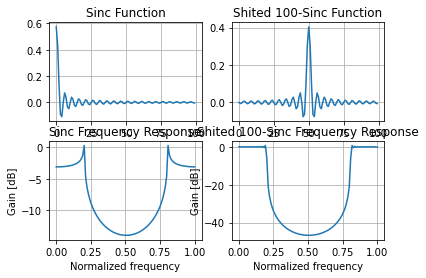

In [7]:
with open('low_pass.pkl', 'rb') as file:
    sinc_pkl, shifted_sinc_pkl, normalized_sinc_pkl, \
    normalized_shifted_sinc_pkl, fft_sinc_magnitude_pkl, \
    fft_sinc_f_pkl, fft_shifted_sinc_magnitude_pkl, fft_shifted_sinc_f_pkl = pickle.load(file)

    
assert np.allclose(sinc_pkl, sinc, atol=0.01)
assert np.allclose(shifted_sinc_pkl, shifted_sinc, atol=0.01)
assert np.allclose(normalized_sinc_pkl, normalized_sinc, atol=0.01)
assert np.allclose(normalized_shifted_sinc_pkl, normalized_shifted_sinc, atol=0.01)
assert np.allclose(fft_sinc_magnitude_pkl, fft_sinc_magnitude, atol=0.01)
assert np.allclose(fft_sinc_f_pkl, fft_sinc_f, atol=0.01)
assert np.allclose(fft_shifted_sinc_magnitude_pkl, fft_shifted_sinc_magnitude, atol=0.01)
assert np.allclose(fft_shifted_sinc_f_pkl, fft_shifted_sinc_f, atol=0.01)


plt.rcParams["figure.figsize"] = (15,10)

plt.subplot(2,2,1)
plt.plot(normalized_sinc)
#plt.stem(normalized_sinc, markerfmt='.', use_line_collection=True)
plt.title('Sinc Function')
plt.grid('on')

plt.subplot(2,2,2)
plt.plot(normalized_shifted_sinc)
#plt.stem(normalized_shifted_sinc, markerfmt='.', use_line_collection=True)
plt.title('Shited {}-Sinc Function'.format(M))
plt.grid('on')

plt.subplot(2,2,3)
fft_sinc_magnitude_reshape = np.copy(fft_sinc_magnitude)

plot_frequency_response(fft_sinc_magnitude_reshape.reshape(-1,1),
                               fft_sinc_f, 
                               title='Sinc Frequency Response')

plt.subplot(2,2,4)
fft_shifted_sinc_magnitude_reshape = np.copy(fft_shifted_sinc_magnitude)

plot_frequency_response(fft_shifted_sinc_magnitude_reshape.reshape(-1,1),
                               fft_shifted_sinc_f, 
                               title='Shited {}-Sinc Frequency Response'.format(M));

## Hamming and Blackman Windows
After developing our low pass filter requirements with the sinc function, we need to define a window function that will complement our filter design. 

A window function is a mathematical function that is zero-valued outside of some chosen interval, normally symmetric around the middle of the interval, maximum near the middle, and usually tapering away from the middle. Mathematically, when another function or waveform/data-sequence is "multiplied" by a window function, the product is also zero-valued outside the interval: all that is left is the part where they overlap, the "view through the window".

In this part, you will develop two window functions, namely the Hamming Window and the Blackman Window. These window functions will have the following prototypes:
* `hamming_window` will get a `BW` parameter that defines the transition bandwidth of the filter and in consequence the length of the filter. The response of the filter is given by
$$w[k] = 0.54 - 0.46 \cdot\cos{\left(\frac{ 2 \pi \cdot x[k]}{M}\right)}$$

* `blackman_window` also recives a parameter `BW` similar to the `hamming_window`. The esponse of the filter is given by
$$w[k] = 0.42 - 0.50 \cdot \cos{\left(\frac{ 2 \pi \cdot x[k]}{M}\right)} + 0.08 \cdot \cos{\left(\frac{ 4 \pi \cdot x[k]}{M}\right)}$$

In [8]:
def hamming_window(BW):
    """ 
    Function that calculates a Hamming window of a given transition bandwidth.
  
    Parameters: 
    BW (float): Transition bandwidth of the filter. The lenght of the filter is 
                given by M=4/BW.
                
    Returns: 
    numpy array: Returns Hamming window of a given M-kernel.
    """
    # Implement the Hamming Window
    ### BEGIN SOLUTION
    M = int(4/BW)
    x = np.arange(0,M,1)
    
    return 0.54 - 0.46*np.cos(2*np.pi*x/M)
    ### END SOLUTION

def blackman_window(BW):
    """ 
    Function that calculates a Blackman window of a given M-kernel.
  
    Parameters: 
    BW (float): Transition bandwidth of the filter. The lenght of the filter is 
                given by M=4/BW.
    Returns: 
    numpy array: Returns Blackman window of a given M-kernel.
    """
    # Implement the Blackman Window
    ### BEGIN SOLUTION
    M = int(4/BW)
    x = np.arange(0,M,1)
    
    return 0.42 - 0.5*np.cos(2*np.pi*x/M) + 0.08*np.cos(4*np.pi*x/M)
    ### END SOLUTION

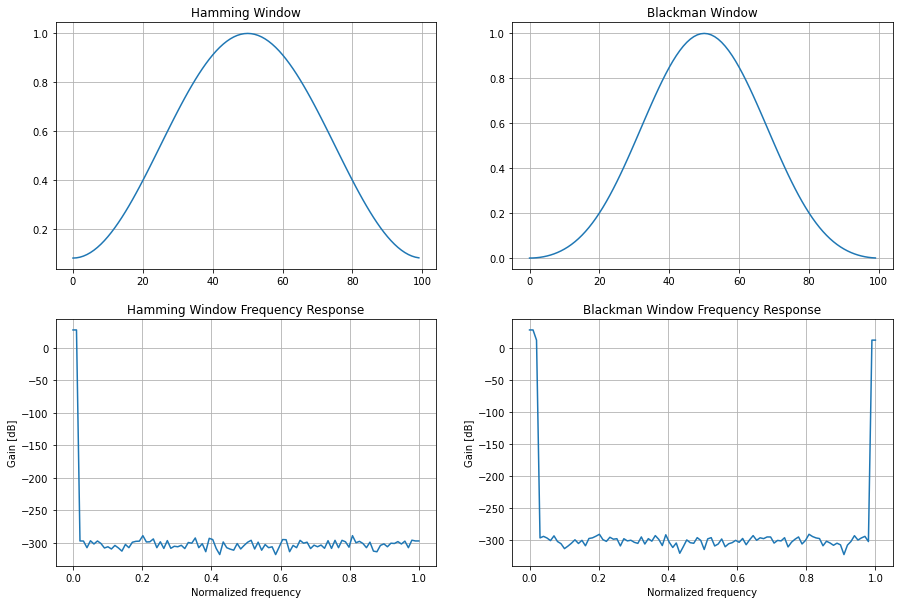

In [9]:
hamming = hamming_window(BW)
blackman = blackman_window(BW)

fft_hamming_magnitude, fft_hamming_f = get_fourier(hamming)
fft_blackman_magnitude, fft_blackman_f = get_fourier(blackman)


with open('hamming_blackman.pkl', 'rb') as file:
    hamming_pkl, blackman_pkl, fft_hamming_magnitude_pkl, \
    fft_hamming_f_pkl, fft_blackman_magnitude_pkl, fft_blackman_f_pkl = pickle.load(file)
    
    
assert np.allclose(hamming_pkl, hamming, atol=0.01)
assert np.allclose(blackman_pkl, blackman, atol=0.01)
assert np.allclose(fft_hamming_magnitude, fft_hamming_magnitude, atol=0.01)
assert np.allclose(fft_hamming_f_pkl, fft_hamming_f, atol=0.01)
assert np.allclose(fft_blackman_magnitude_pkl, fft_blackman_magnitude, atol=0.01)
assert np.allclose(fft_blackman_f_pkl, fft_blackman_f, atol=0.01)


plt.rcParams["figure.figsize"] = (15,10)

plt.subplot(2,2,1)
plt.plot(hamming)
#plt.stem(hamming, markerfmt='.', use_line_collection=True)
plt.title('Hamming Window')
plt.grid('on')

plt.subplot(2,2,2)
plt.plot(blackman)
#plt.stem(blackman, markerfmt='.', use_line_collection=True)
plt.title('Blackman Window')
plt.grid('on')

plt.subplot(2,2,3)
plot_frequency_response(fft_hamming_magnitude.reshape(-1,1), 
                               fft_hamming_f, 
                               title='Hamming Window Frequency Response')

plt.subplot(2,2,4)
plot_frequency_response(fft_blackman_magnitude.reshape(-1,1), 
                               fft_blackman_f, 
                               title='Blackman Window Frequency Response')
plt.show()

## Merge Sinc and Window
Now that we have our sinc and window functions, the process to generate the Low-Pass filter consist on multiplying both filters. This new filter would have a finite impulse response and a flat frequency response on the band pass region.

In [10]:
# Merge the normalized shifted sinc filter and the Hamming window. Assign the result to to h0.
### BEGIN SOLUTION
h0 = normalized_shifted_sinc*hamming
### END SOLUTION

# Merge the normalized shifted sinc filter and the Blackman window. Assign the result to to h1.
### BEGIN SOLUTION
h1 = normalized_shifted_sinc*blackman
### END SOLUTION

# Assign to H0 and f0 the Fourier Transform magnitude and normalized frequency of h0 respectively.
### BEGIN SOLUTION
H0, f0 = get_fourier(h0)
### END SOLUTION

# Assign to H1 and f1 the Fourier Transform magnitude and normalized frequency of h1 respectively.
### BEGIN SOLUTION
H1, f1 = get_fourier(h1)
### END SOLUTION

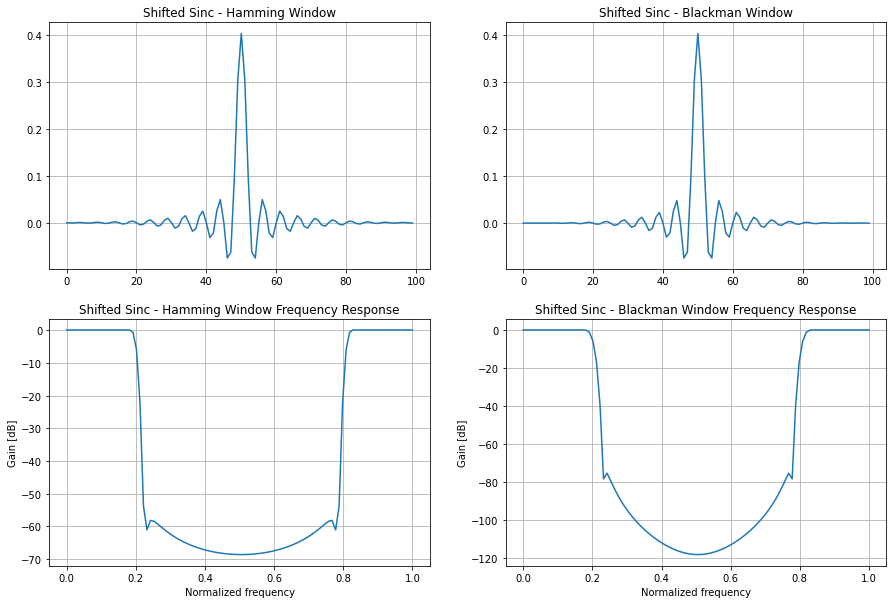

In [11]:
with open('merge.pkl', 'rb') as file:
    h0_pkl, h1_pkl, H0_pkl, f0_pkl, H1_pkl, f1_pkl = pickle.load(file)
    
    
assert np.allclose(h0_pkl, h0, atol=0.01)
assert np.allclose(h1_pkl, h1, atol=0.01)
assert np.allclose(H0_pkl, H0, atol=0.01)
assert np.allclose(f0_pkl, f0, atol=0.01)
assert np.allclose(H1_pkl, H1, atol=0.01)
assert np.allclose(f1_pkl, f1, atol=0.01)


plt.rcParams["figure.figsize"] = (15,10)

plt.subplot(2,2,1)
plt.plot(h0)
#plt.stem(hamming_shifted_sinc, markerfmt='.', use_line_collection=True)
plt.title('Shifted Sinc - Hamming Window')
plt.grid('on')

plt.subplot(2,2,2)
plt.plot(h1)
#plt.stem(blackman_shifted_sinc, markerfmt='.', use_line_collection=True)
plt.title('Shifted Sinc - Blackman Window')
plt.grid('on')

plt.subplot(2,2,3)
H0_reshape = np.copy(H0)
plot_frequency_response(H0_reshape.reshape(-1,1), f0, title='Shifted Sinc - Hamming Window Frequency Response')

plt.subplot(2,2,4)
H1_reshape = np.copy(H1)
plot_frequency_response(H1_reshape.reshape(-1,1), f1, title='Shifted Sinc - Blackman Window Frequency Response')

plt.show()

## Comparison between Hamming and Blackman windows
The Hamming window has a **faster roll-off** than the Blackman, however the Blackman has a **better stopband attenuation**. To be exact, the stopband attenuation for the Blackman is greater than the Hamming. Although it cannot be seen in these graphs, the Blackman has a very small passband ripple compared to the the Hamming. In general, the **Blackman should be your first choice**; a slow roll-off is easier to handle than poor stopband attenuation. 


## Example of a filter design for an EEG signal
An electroencephalogram, or EEG, is a measurement of the electrical activity of the brain. It can be detected as millivolt level signals appearing on electrodes attached to the surface of the head. Each nerve cell in the brain generates small electrical pulses. The EEG is the combined result of an enormous number of these electrical pulses being generated in a (hopefully) coordinated manner. Although the relationship between thought and this electrical coordination is very poorly understood, different frequencies in the EEG can be identified with specific mental states. If you close your eyes and relax, the predominant EEG pattern will be a slow oscillation between about 7 and 12 hertz. This waveform is called the alpha rhythm, and is associated with contentment and a decreased level of attention. Opening your eyes and looking around causes the EEG to change to the beta rhythm, occurring between about 17 and 20 hertz. Other frequencies and waveforms are seen in children, different depths of sleep, and various brain disorders such as epilepsy.

In this example, we will assume that the EEG signal has been amplified by analog electronics, and then digitized at a sampling rate of 100 samples per second. We have a dataset of 640 samples. Our goal is to separate the alpha from the beta rhythms. To do this, we will design a digital low-pass filter with a cutoff frequency of 14 hertz, and a transition bandwidth of 4 hertz.

In [12]:
# Load data
ecg = np.loadtxt(fname = "ecg.dat").flatten()

# Find the normalized cut-off frequency and assign it to fc.
# Remember that the normalized frequency is the analog frequency 
# divided by the sampling frequency.
### BEGIN SOLUTION
fc = 0.14
### END SOLUTION

# Find the normalized transition bandwidth and assign it to BW.
### BEGIN SOLUTION
BW = 0.04
### END SOLUTION

print("Filter lenght is {}".format(M))

# Implement a Hamming windowed sinc filter with the fc an BW values specified.
# Assing the result to a variable named h
### BEGIN SOLUTION
shifted_sinc = shifted_sinc_function(fc, BW)
normalized_shifted_sinc = shifted_sinc/np.sum(shifted_sinc)
hamming = hamming_window(BW)
h = normalized_shifted_sinc*hamming
### END SOLUTION

# Convolve (Filter) your signal with your Hamming windowed sinc filter.
# For this use np.convolve and mode 'same' and assign your result to filtered_ecg
### BEGIN SOLUTION
filtered_ecg = np.convolve(ecg, h, mode='same')
### END SOLUTION

Filter lenght is 100


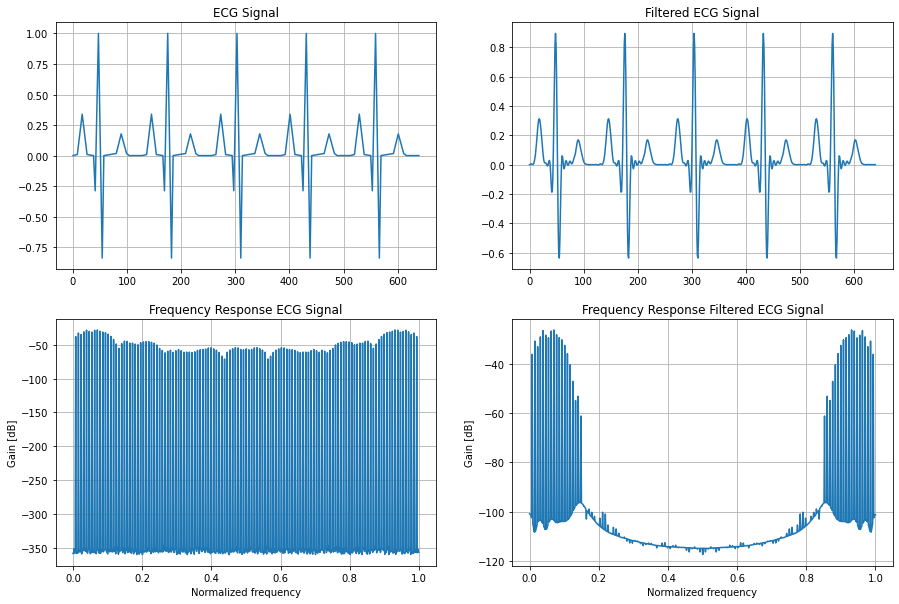

In [13]:
with open('ecg.pkl', 'rb') as file:
    h_pkl, filtered_ecg_pkl = pickle.load(file)
    
assert np.allclose(h_pkl, h, atol=0.01)
assert np.allclose(filtered_ecg_pkl, filtered_ecg, atol=0.01)


filter_magnitude, filter_f= get_fourier(h)
normalized_fft_hamming_shifted_sinc = np.absolute(filter_magnitude)/np.sum(np.absolute(filter_magnitude))

fft_ecg_magnitude, fft_ecg_f = get_fourier(ecg)
normalized_fft_ecg = np.absolute(fft_ecg_magnitude)/np.sum(np.absolute(fft_ecg_magnitude))

fft_filtered_ecg_magnitude, fft_filtered_ecg_f = get_fourier(filtered_ecg)
normalized_fft_filtered_ecg = np.absolute(fft_filtered_ecg_magnitude)/np.sum(np.absolute(fft_filtered_ecg_magnitude))


plt.rcParams["figure.figsize"] = (15,10)

plt.subplot(2,2,1)
plt.plot(ecg)
plt.title('ECG Signal')
plt.grid('on')

plt.subplot(2,2,2)
plt.plot(filtered_ecg)
plt.title('Filtered ECG Signal')
plt.grid('on')


plt.subplot(2,2,3)
normalized_fft_ecg_reshape = normalized_fft_ecg + 1e-18
plot_frequency_response(normalized_fft_ecg_reshape.reshape(-1,1), 
                               fft_ecg_f, 
                               title='Frequency Response ECG Signal')

plt.subplot(2,2,4)
normalized_fft_filtered_ecg_reshape = normalized_fft_filtered_ecg + 1e-18
plot_frequency_response(normalized_fft_filtered_ecg_reshape.reshape(-1,1), 
                               fft_filtered_ecg_f, 
                               title='Frequency Response Filtered ECG Signal')

## Saving our filter
We will pickle our filter design for later user in the next Jupyter Notebook.

In [14]:
data = {'ecg':ecg, 
        'low_pass':h, 
        'fft_low_pass':normalized_fft_hamming_shifted_sinc}

with open('save_data.pickle', 'wb') as file:
    pickle.dump(data, file)

#### Reference
* http://www.dspguide.com/ch16.htm
* https://numpy.org/doc/stable/reference/generated/numpy.convolve.html